<a href="https://colab.research.google.com/github/abbycammarano/Analysis-of-Women-vs.-Men-in-STEM-Fields-by-Median-Salary/blob/main/Women-vs.-Men-in-STEM-Fields-by-Median-Salary.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Introduction to Critical AI Studies Final Project**: Analysis of Women vs. Men in STEM Fields by Median Salary

*Abigail Cammarano*

**Link to AI Attestation Cover Sheet:**
https://docs.google.com/document/d/1PgPKkd6rGWw0QlGB7bDyDNOktD_02ZyYdb3KuO6xROI/edit?usp=sharing

**Introduction:**

Science, Technology, Engineering, and Mathematics (STEM) fields are majority male. MIT Professional Education states that women make up only 28% of STEM fields (Piloto). Science.org states that the ratio of males to females in STEM is approximately 4:1 (Cimpian and King). As a woman in STEM (specifically statistics) myself, I believe that this fact is largely felt. Women, especially women in male dominated fields like STEM fields, do not reap the same benefits that males do. The National Center for Science and Engineering Statistics states that males in STEM fields have a higher median income than women in STEM fields (NCSES). For my final project, I chose to investigate via a simple linear regression to what extent women in STEM are excluded from benefits and equal payouts. In the context of my linear regression that I will later run, these fields I include as "STEM" are the fields that the American Community Survey defined as STEM fields (essentially any fields relating to science, technology, engineering or mathematics), ranging anywhere from petroleum engineering to zoology (US Census Bureau). My guiding research question throughout was to what extent the proportion of women out of the total number in a certain STEM field impacts the median income of that entire field. Before beginning this process of conducting a regression, I hypothesized that there would be a negative correlation between the share of women in a STEM field and the median income of that field (so as the proportion of women rises, the median income of that field decreases).

**Important Packages:**


In [ ]:
# load in necessary packages
install.packages("ggplot2")
install.packages("car")
install.packages("faraway")
install.packages("alr4")
install.packages("outliers")
library(ggplot2)
library(car)
library(faraway)
library(alr4)
library(outliers)
library(readr)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘microbenchmark’, ‘rbibutils’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘mitools’, ‘survey’, ‘estimability’, ‘insight’, ‘effects’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Loading required package: carData

Registered S3 method overwritten by 'lme4':
  method           from
  na.action.merMod car 


Attaching package: ‘

**Simple Linear Regression:**

Simple linear regression is a statistical model used to predict a response variable (dependent) based on a predictor variable (independent) (OARC). In order to do so, based on the inputted data points, a line that best fits through those points is formed. I will be implementing this process to investigate my research question and find a line of best fit Y = B0 + B1 + ε.

**Choice of dataset and loading it in:**

I chose to utilize a dataset that we had explored in past quarters, "women-stem.csv" from a larger folder of other college major-related csvs on Github (Github). I chose this dataset for my regression process as it already had a variable "ShareWomen" which categorized the presence of women in STEM fields by the proportion of women as a share of the total. ShareWomen I decided would be my independent variable. Additionally, the variable "Median" which represents median income of a STEM field I decided would be my dependent variable for the regression. I acknowledge my bias that at this point in my process, I was essentially looking for a dataset that would lend well to what variables/numbers I wanted to analyze, rather than looking at the larger context. My dataset is: https://drive.google.com/file/d/1CNnl9wbFGqVRJFXWEWAlhJc82EX_fA94/view?usp=sharing

In [ ]:
## load in the data
women_stem <- read.csv("women-stem.csv")
head(women_stem) # print first few rows
## create regression mode
womenstem_lm <- lm(Median ~ ShareWomen, data = women_stem)


,Rank,Major_code,Major,Major_category,Total,Men,Women,ShareWomen,Median
,<int>,<int>,<chr>,<chr>,<int>,<int>,<int>,<dbl>,<int>
1,1,2419,PETROLEUM ENGINEERING,Engineering,2339,2057,282,0.1205643,110000
2,2,2416,MINING AND MINERAL ENGINEERING,Engineering,756,679,77,0.1018519,75000
3,3,2415,METALLURGICAL ENGINEERING,Engineering,856,725,131,0.1530374,73000
4,4,2417,NAVAL ARCHITECTURE AND MARINE ENGINEERING,Engineering,1258,1123,135,0.1073132,70000
5,5,2418,NUCLEAR ENGINEERING,Engineering,2573,2200,373,0.1449670,65000
6,6,2405,CHEMICAL ENGINEERING,Engineering,32260,21239,11021,0.3416305,65000


**Ordinary Least Squares:**

Because there is always some error or noise in the dependent variable that cannot be explained by the relationship between independent and dependent variables, Y can never be an exact function of X. In order to account for this, there is a method of predicting the mean value of the outcome for a given value of the predictor variable that includes error terms to account for these noises in the dependent variable. To make this "best guess" of a linear relationship, we want a line that best fits our data, utilizing a method called Ordinary Least Squares (OLS). The "line of best fit" from this process will be of the form Y = B0 + B1 + ε where epsilon is the random error term. This is one key limitation of the linear regression model to address: in order for the predictions and conclusions of a simple linear regression to be applicable and mathematically accurate, the conditions/assumptions of the OLS must first be met. These conditions include the errors have a mean almost equal to 0, errors are independent, errors have equal variances (homoscedasticity), and a linear relationship between the independent and dependent variable (linearity). When referencing errors, I am referencing the residuals (the difference in the predicted and actual values of the response variable). While these conditions may not be exactly met all the time, if we can roughly meet these four conditions, we can proceed with the linear regression process I have outlined below. All of my information on how to construct a simple linear regression and on OLS comes from the UCLA technological workshop "Introduction to Regression in R" (OARC).

In [ ]:
# check necessary conditions for using Ordinary Least Squares method
  # 1: errors have mean equal to 0
  women_stem$residuals <- residuals(womenstem_lm)
  women_stem$fitted_values <- fitted(womenstem_lm)
  mean(women_stem$residuals) # very close to 0!!!


[1] -2.131628e-13

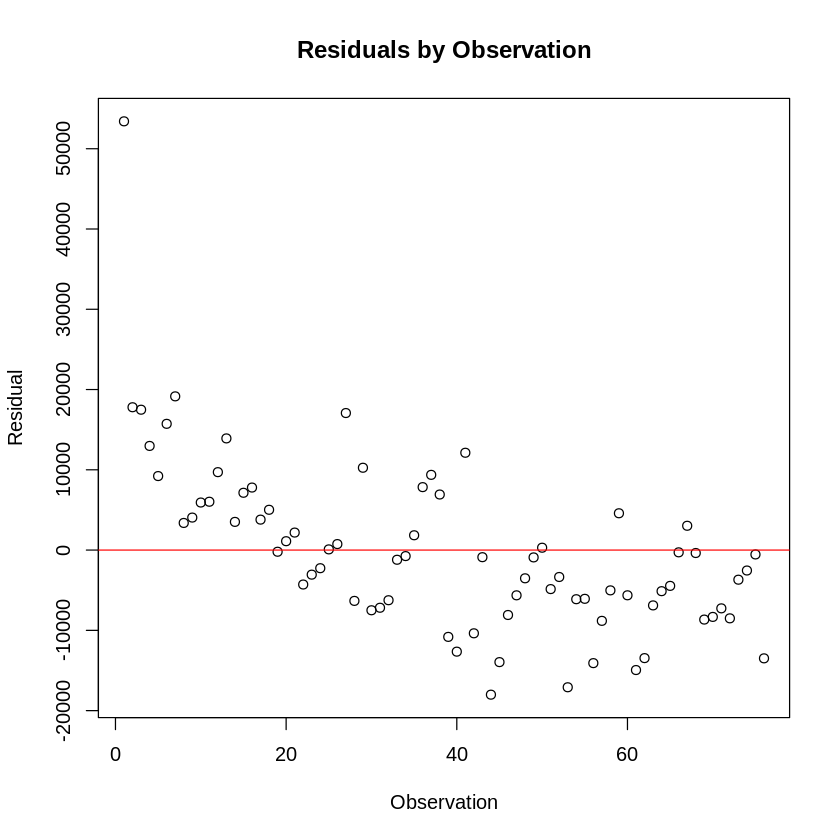

In [ ]:
# 2: errors are independent
  plot(women_stem$residuals, xlab = "Observation", ylab = "Residual", main = "Residuals by Observation")
  abline(h = 0, col = "red")

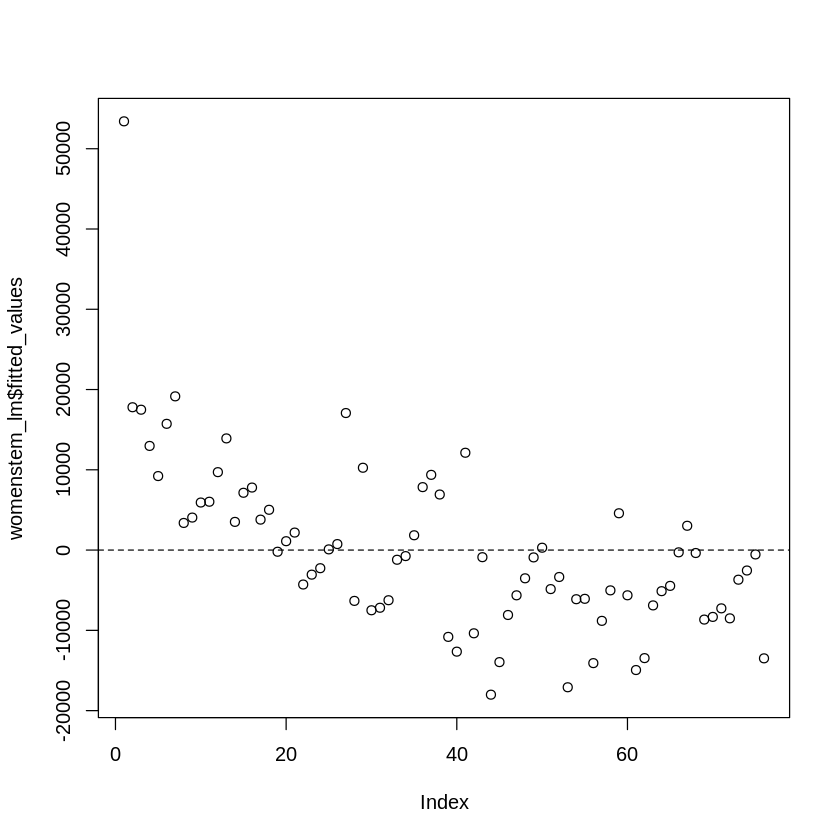

In [ ]:
# 3: errors have equal variances (homoscedasticity), plot around mean of errors (0)
  plot(womenstem_lm$residuals, womenstem_lm$fitted_values)
  abline(h = 0, lty = 2)

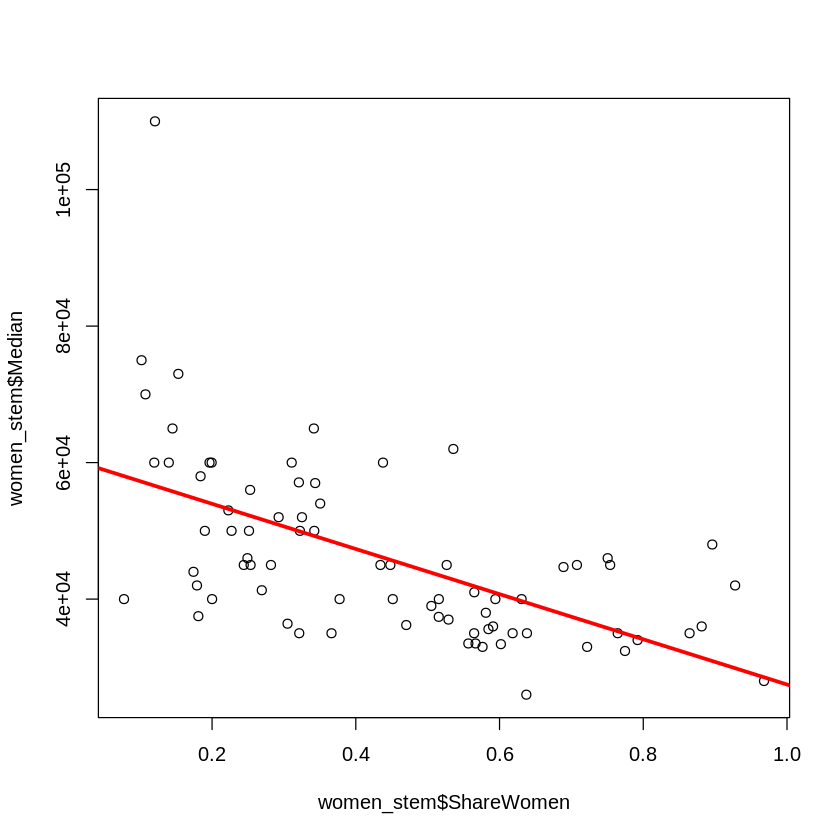

In [ ]:
 # 4: relationship of dependent and independent variables is linear (linearity)
  plot(women_stem$Median ~ women_stem$ShareWomen) # linear appearance of plot proves this
  abline(womenstem_lm, col = "red", lwd = 3)

In step 1, the mean of the errors is extremely close to 0. In step 2, there is a roughly random scatter around 0 (no obvious pattern). In step 3, there is a roughly equal spread of residuals across the fitted values (no glaring funnel shape). In step 4, there is a linear pattern between the independent and dependent variables. With this, I have confirmed that the conditions for OLS have been roughly met. Although there is one data point in the top left corner with a very large residual (error), I will continue with my regression model while acknowledging this extreme outlier as an unusual point in the dataset.  I can now proceed in my process of conducting linear regression to create a model that predicts a STEM field's median income based on the proportion of women in that field.

**Regression Model:**

In [ ]:
## find coefficients for regression line
womenstem_lm <- lm(Median ~ ShareWomen, data = women_stem)
summary(womenstem_lm)
predict(womenstem_lm)


Call:
lm(formula = Median ~ ShareWomen, data = women_stem)

Residuals:
   Min     1Q Median     3Q    Max 
-18014  -6471   -900   5246  53413 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)    60576       2651  22.847  < 2e-16 ***
ShareWomen    -33090       5366  -6.166 3.37e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 10790 on 74 degrees of freedom
Multiple R-squared:  0.3394,	Adjusted R-squared:  0.3305 
F-statistic: 38.02 on 1 and 74 DF,  p-value: 3.369e-08


1        2        3        4        5        6        7        8 
56586.97 57206.17 55512.44 57025.46 55779.49 49271.87 42849.61 56620.24 
       9       10       11       12       13       14       15       16 
55950.70 54075.90 53977.87 50291.38 46088.06 54488.37 49961.67 49210.89 
      17       18       19       20       21       22       23       24 
52205.99 48980.28 53207.46 50894.06 49819.13 54290.32 53061.10 52257.97 
      25       26       27       28       29       30       31       32 
49914.09 49252.07 30927.09 52330.73 35743.23 52499.06 52185.36 51247.15 
      33       34       35       36       37       38       39       40 
46205.47 45748.82 43155.32 37157.97 35628.91 37777.40 54814.73 54653.93 
      41       42       43       44       45       46       47       48 
29875.21 51668.81 41884.99 58013.53 53957.69 48087.02 45637.43 43517.07 
      49       50       51       52       53       54       55       56 
40914.06 39705.98 43861.30 41352.82 54591.03 43521.60 43072.81 50483.82 
      57       58       59       60       61       62       63       64 
45017.59 41020.17 31414.34 41233.43 49944.74 48459.63 41892.48 40119.39 
      65       66       67       68       69       70       71       72 
39460.11 35281.50 31971.51 34365.93 42158.38 41826.26 40660.90 41504.64 
      73       74       75       76 
36689.83 34945.63 28545.29 39488.35

`geom_smooth()` using formula = 'y ~ x'


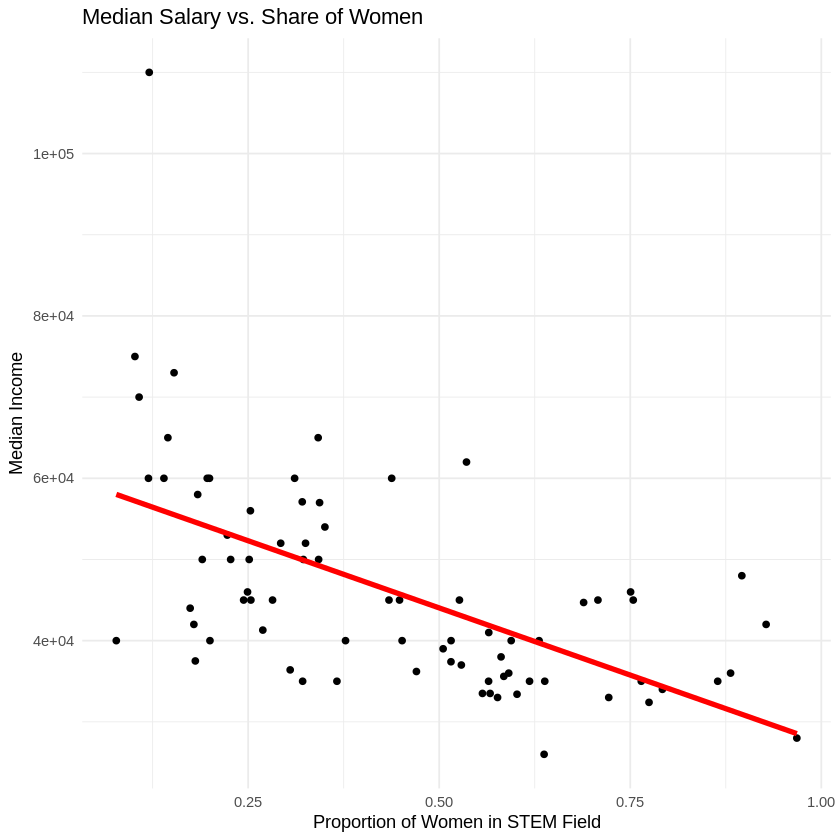

In [ ]:
## plot regression (using ggplot2)
ggplot(data = women_stem) +
  geom_point(aes(x = ShareWomen, y = Median)) +
  geom_smooth(aes(x = ShareWomen, y = Median),
  method = "lm",
  se = FALSE,
  color = "red",
  linewidth = 1.5) +
  labs(x = "Proportion of Women in STEM Field", y = "Median Income", title = "Median Salary vs. Share of Women") +
  theme_minimal()

**Investigation of Outliers:**

  rstudent unadjusted p-value Bonferroni p
1 6.189532         3.1822e-08   2.4184e-06

,StudRes,Hat,CookD
,<dbl>,<dbl>,<dbl>
1,6.18953167,0.03791393,0.501841845
7,1.81633098,0.01557162,0.025305916
27,1.65571502,0.06528934,0.093541583
41,1.16982872,0.07275865,0.053425560
75,-0.05241324,0.08291787,0.000125888


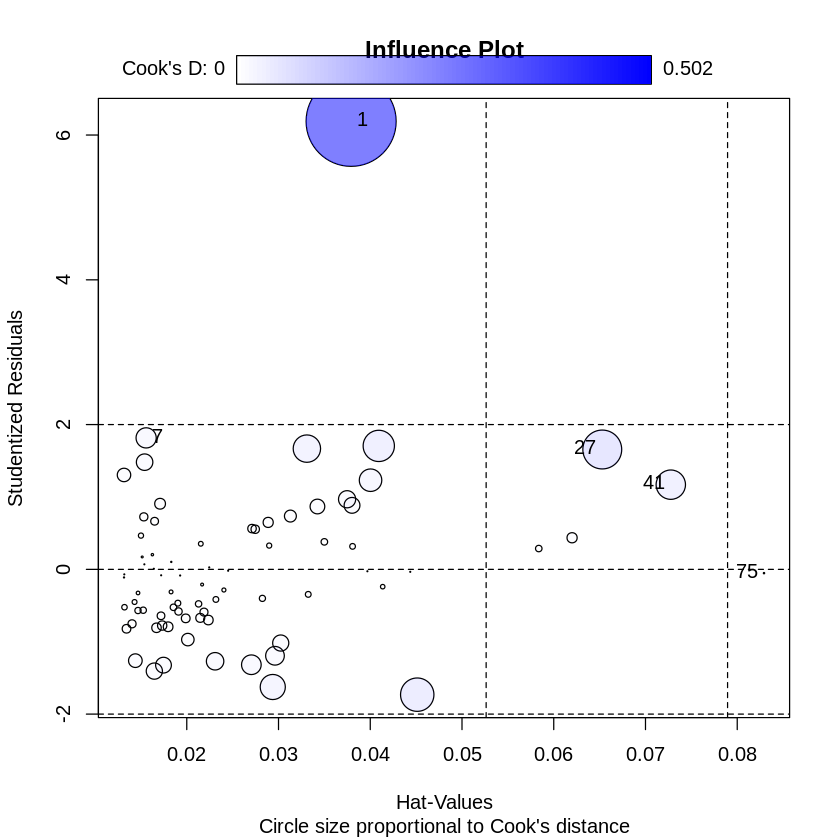

In [ ]:
# investigating unsual points: outliers, leverage points, influence points
outlierTest(womenstem_lm)
influencePlot(womenstem_lm, main = "Influence Plot", sub = "Circle size proportional to Cook's distance")

By looking at the plot of the regression above, we can see that all the data seem to roughly fall on the line of best fit, other than an obvious unusual point in the top left corner, very distant from the rest of the data.

Based on the output of outlierTest, observation one is an outlier of the dataset. The studentized residual (rstud) of observation number one is greater than 3, so it is an outlier. Further, the Bonferroni p-value is less than 0.05, so it is a statistically significant outlier.

Looking at the influence plot, observation one has a very large Cook's distance, represented by a much larger circle in comparison to the others. This essentially means that it is a highly influential point of the dataset, and its removal could have significant effects on the regression line.


**Linear Regression Process and Accomplishments:**

Utilizing the above coefficients, the equation for my simple linear regression is Median = 60576 - 33090(ShareWomen) + ε. This equation and my visualization of it through ggplot2 indicate that there is a strong, negative, linear relationship between the proportion of women in a STEM field and the median income of that field. The intercept indicates that when ShareWomen of a field is 0, the median income is 60576, an extrapolated number (not realistic in context). The slope indicates that as ShareWomen of a field increases by one unit, the predicted Median income decreases by 33,090.

The data that the NCSES used to conclude that men in STEM fields make more income than women in STEM is also based on ACS data (but more recent, 2021) data, therefore it is not surprising that I also concluded similar results.

**As the proportion of women in a STEM field increases, the median income of that field tends to decrease according to this simple linear regression. But due to the many limitations of the dataset and the linear regression model, this conclusion should not be interpreted as causal, or broadly applied without further questioning.**


**Limitations of my dataset:**

  My choosing of the dataset based on the niceness of variables that I wanted to utilize (and not necessarily reaching further to find variables that more accurately depict society, such as a dataset with more gender categories) is directly related to "Do Datasets Have Politics", where the authors explore that datasets are not neutral artifacts, but that they depict the biases and priorities of the creator and user (Scheuerman, et al.). Datasets often prioritize universal application over ethics and context, leading to harms and stereotypes embedded inside of them (Scheuerman, et al.), reinforcing the concept that we cannot have utter faith in statistical methods just because they are advertised to us as "objective". It is key to note that many of the people who are trying to convince us of some fact using numbers as "objective evidence", have in reality chosen the numbers/datasets that they present to us, just as I have.


  One glaring downfall of my chosen dataset is that it is outdated, taken from American Community Survey data from 2010-2012. Once I found the women-stem.csv dataset on Github, I attempted to utilize the most recent (2024) American Community Survey data to construct and clean up a dataset similar to the one I found on Github and with similarly calculated variables like ShareWomen. I found a few difficulties in this process of trying to construct my own dataset: the csv was not reading into the R script well and the format kept getting messed up (meaning I could not cleanly code with it and create the columns/variables I desired) and two that I was struggling to find what variables the Github creators had actually utilized in making women-stem.csv and how they manipulated/cleaned the numbers into the final dataset. This poor documentation of the Github dataset ultimately leads to less reproducibility of the dataset for those who want to build on the work, illustrating the fact that not only the manner in which datasets are created, but the manner in which they are documented has impact and illustrates the priorities of the creator (Scheuerman, et al.).

  Another limitation of my chosen dataset is that there are only two categories for gender: male and female, making it a non-representative sample, something that leads to biases in linear regression (ScienceInsights). We can view gender as both a social and technological category. In society, gender is a complex, fluid category. But when we think of technological categories, algorithms desire numerically usable categories, like a binary option (0 or 1). In "Misgendering Algorithms", the authors explore this relation between the social construct of gender versus its algorithmic application, and how most algorithms utilize a "simplistic binary understanding" of gender, simplifying a complex concept all the way into two categories (Fosch-Villaronga, et al.). This controlled vocabulary already excludes and underrepresents people who identify as otherwise, perpetuating the demographic biases that exist in society. In "On the Dangers of Stochastic Parrots: Can Language Models Be Too Big?", a reading we discussed in winter quarter, the authors explore that one of the  dangers of large language models is that they are trained on datasets with limited diversity, ultimately continuing biases and stereotypes in society (Bender, et al.). While I was not actually training a large language model, this concept still relates to my usage of a dataset that had limited diversity within it. The authors discuss that real-world deployment of models trained on problematic data replicates existing social inequities, ultimately harming communities, depicting the potential harms of my own linear regression that was based on non-representative data. Because of this, my linear regression on this dataset has biases, and cannot be viewed as objectively accurate or representative of society. This reduction/ignoring of human identity in favor of prioritizing a clean, simple algorithm directly depicts one of the fallbacks of linear regression and why it should not be broadly applied without investigation.




**Limitations of linear regression:**

One of the origins of linear regression is Francis Galton's work on the inherited traits of sweet peas, where he studied the lengths of the offspring and found that the offspring of taller parents tended to be taller, but tended to be less extreme than their parents, developing the idea of averaging toward the mean (Stanton). Then, he and Karl Pearson expanded upon these ideas to develop fundamental concepts of regression and correlation coefficient (Stanton). Simply the name Galton can tell us that the origin story of linear regression is deeply entangled with harmful and biased practices/theories like eugenics.

There are necessary assumptions that come with this machine learning method, such as the Ordinary Least Squares assumptions that I discussed above. Thus, we cannot fit any variables from any dataset to a linear model.

Furthermore, this statistical model requires numeric inputs, forcing humans and our behaviors to be deduced to numbers. This process essentially takes pools of data and averages them out to predict what the expected outcome/response would be. For something less consequential like predicting income, it may seem normal or even positive to conduct this averaging of numbers, but for something with higher stakes, like predicting crime, deducing humans into numbers becomes dangerous. Francis Galton's "Composite Portraits" that we discussed in fall quarter serves as an example of someone averaging data out to make a prediction, as Galton superimposes images onto one another to create an "average" of a certain "type" of person (Galton). Galton's portraits demonstrate the extreme dangers that come when taking averages of data and compiling them goes too far, such as discrimination, stereotyping, and eugenics.

There are a multitude of other factors that lead to bias in linear regression like omitting important variables (i.e. ShareWomen is not the only factor that impacts median income) and measurement error in predictor variables (ScienceInsights). Confounding variables that also impact the response variable prevent us from concluding that correlation equals causation, so just because there is a negative correlation between ShareWomen and median income, that does not mean ShareWomen solely predicts the decrease in income.

**Conclusion:**

My linear regression illustrated a strong, negative, linear relation between the proportion of women in a STEM field and the median income of that field. This regression illustrated one major outlier/influential point in the dataset that greatly influenced the regression.

While it is helpful to have statistical methods such as a simple linear regression to make conclusions and predictions about our surroundings, it is crucial to acknowledge the extreme biases that lie behind the functioning of the model and the datasets used to create them. In an era where numbers are increasingly used to categorize, we must refrain from over-simplifying people and their identities and from applying those outputs broadly in order to prevent exclusionary practices and the perpetuation of harmful outputs.

**Works Cited**

Bender, Emily, et al. “On the Dangers of Stochastic Parrots: Can Language Models Be Too Big? .” FAccT ’21: Proceedings of the 2021 ACM Conference on Fairness, Accountability, and Transparency, 1 Mar. 2021, pp. 610–623, https://doi.org/10.1145/3442188.3445922.

Cimpian, Joseph R, and Jo R King. “An Institution-Level Analysis of Gender Gaps in STEM over Time.” Science, vol. 386, no. 6724, 21 Nov. 2024, pp. 853–856, https://doi.org/10.1126/science.adr0787.

“Data/College-Majors/Women-Stem.csv at Master · Fivethirtyeight/Data.” GitHub, github.com/fivethirtyeight/data/blob/master/college-majors/women-stem.csv.

Fosch-Villaronga, Eduard, et al. “Misgendering Algorithms: Insights from a Cross-Sectional Survey on Algorithmic Gender Classification in Social Media.” Technology in Society, vol. 84, 18 Oct. 2025, p. 103110, www.sciencedirect.com/science/article/pii/S0160791X25003008, https://doi.org/10.1016/j.techsoc.2025.103110.

Galton, Francis. “Composite Portraits, Made by Combining Those of Many Different Persons into a Single Resultant Figure.” The Journal of the Anthropological Institute of Great Britain and Ireland, vol. 8, 1879, pp. 132–144, www.jstor.org/stable/pdf/2841021.pdf?refreqid=excelsior%3Ab7629804e423d8332fd846a9a469da96, https://doi.org/10.2307/2841021. Accessed 6 Mar. 2019.

Piloto, Clara. “The Gender Gap in STEM: Still Gaping in 2023.” MIT Professional Education, 13 Mar. 2023, professionalprograms.mit.edu/blog/leadership/the-gender-gap-in-stem/.

Scheuerman, Morgan Klaus, et al. “Do Datasets Have Politics? Disciplinary Values in Computer Vision Dataset Development.” Proceedings of the ACM on Human-Computer Interaction, vol. 5, no. CSCW2, 13 Oct. 2021, pp. 1–37, https://doi.org/10.1145/3476058.

Stanton, Jeffrey M. “Galton, Pearson, and the Peas: A Brief History of Linear Regression for Statistics Instructors.” Journal of Statistics Education, vol. 9, no. 3, Jan. 2001, https://doi.org/10.1080/10691898.2001.11910537.

States, United. “Explore Census Data.” Census.gov, 2026, data.census.gov/all?q=American+Community+Survey&d=ACS+1-Year+Supplemental+Estimates. Accessed 9 June 2026.

“The STEM Labor Force: Scientists, Engineers, and Skilled Technical Workers | NSF - National Science Foundation.” Ncses.nsf.gov, 30 May 2024, ncses.nsf.gov/pubs/nsb20245/representation-of-demographic-groups-in-stem.

UCLA Office of Advanced Research Computing (OARC). “Introduction to Regression in R.” YouTube, 1 Apr. 2022, www.youtube.com/watch?v=pnko6ZSw2D8. Accessed 4 June 2026.

“What Is Bias in Linear Regression? Causes and Effects.” ScienceInsights, 10 Mar. 2026, scienceinsights.org/what-is-bias-in-linear-regression-causes-and-effects/. Accessed 10 June 2026.